<a href="https://colab.research.google.com/github/Swathims1/BIS-LAB/blob/main/PCA_Week02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Iteration  1: Best x = 29, Fitness = 1151
Iteration  2: Best x = 29, Fitness = 1151
Iteration  3: Best x = 29, Fitness = 1151
Iteration  4: Best x = 29, Fitness = 1151
Iteration  5: Best x = 29, Fitness = 1151
Iteration  6: Best x = 29, Fitness = 1151
Iteration  7: Best x = 29, Fitness = 1151
Iteration  8: Best x = 29, Fitness = 1151
Iteration  9: Best x = 29, Fitness = 1151
Iteration 10: Best x = 29, Fitness = 1151
Iteration 11: Best x = 29, Fitness = 1151
Iteration 12: Best x = 29, Fitness = 1151
Iteration 13: Best x = 29, Fitness = 1151
Iteration 14: Best x = 29, Fitness = 1151
Iteration 15: Best x = 29, Fitness = 1151
Iteration 16: Best x = 29, Fitness = 1151
Iteration 17: Best x = 29, Fitness = 1151
Iteration 18: Best x = 29, Fitness = 1151
Iteration 19: Best x = 29, Fitness = 1151
Iteration 20: Best x = 29, Fitness = 1151
Iteration 21: Best x = 29, Fitness = 1151
Iteration 22: Best x = 29, Fitness = 1151
Iteration 23: Best x = 29, Fitness = 1151
Iteration 24: Best x = 29, Fitness

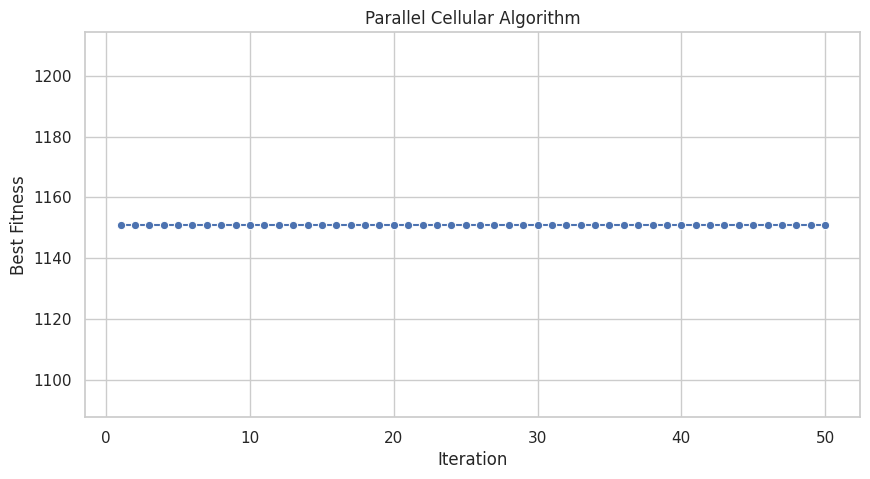

In [ ]:
import random
import matplotlib.pyplot as plt
import seaborn as sns


# --------------------------------------------------
# 1. Fitness Function
# --------------------------------------------------

def fitness(x):
    return x ** 2 + 10 * x + 20


# --------------------------------------------------
# 2. Parameters
# --------------------------------------------------

NUM_CELLS = 10
ITERATIONS = 50
MIN_X = 0
MAX_X = 31


# --------------------------------------------------
# 3. Initialize Cells
# --------------------------------------------------

def initialize_cells():
    return [random.randint(MIN_X, MAX_X)
            for _ in range(NUM_CELLS)]


# --------------------------------------------------
# 4. Find Neighbors
# --------------------------------------------------

def get_neighbors(cells, index):

    neighbors = []

    # Left neighbor
    if index > 0:
        neighbors.append(cells[index - 1])

    # Right neighbor
    if index < NUM_CELLS - 1:
        neighbors.append(cells[index + 1])

    return neighbors


# --------------------------------------------------
# 5. Parallel Cellular Algorithm
# --------------------------------------------------

def cellular_algorithm():

    cells = initialize_cells()

    best_x = cells[0]
    best_fitness = fitness(best_x)

    fitness_history = []

    for iteration in range(ITERATIONS):

        # Store new states separately
        new_cells = cells.copy()

        # Update every cell
        for i in range(NUM_CELLS):

            current_x = cells[i]
            current_fitness = fitness(current_x)

            neighbors = get_neighbors(cells, i)

            if neighbors:

                # Find best neighboring cell
                best_neighbor = max(
                    neighbors,
                    key=fitness
                )

                # Move toward better neighbor
                if fitness(best_neighbor) > current_fitness:
                    new_cells[i] = best_neighbor

        # Replace old cells
        cells = new_cells

        # Find best cell
        current_best_x = max(cells, key=fitness)
        current_best_fitness = fitness(current_best_x)

        # Update global best
        if current_best_fitness > best_fitness:
            best_x = current_best_x
            best_fitness = current_best_fitness

        fitness_history.append(best_fitness)

        print(
            f"Iteration {iteration + 1:2d}: "
            f"Best x = {best_x}, "
            f"Fitness = {best_fitness}"
        )

    return best_x, best_fitness, fitness_history


# --------------------------------------------------
# 6. Run Algorithm
# --------------------------------------------------

best_x, best_fitness, fitness_history = \
    cellular_algorithm()


# --------------------------------------------------
# 7. Final Result
# --------------------------------------------------

print("\n===== FINAL RESULT =====")
print("Best x:", best_x)
print("Maximum Fitness:", best_fitness)


# --------------------------------------------------
# 8. Visualization
# --------------------------------------------------

sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 5))

sns.lineplot(
    x=range(1, ITERATIONS + 1),
    y=fitness_history,
    marker="o"
)

plt.title("Parallel Cellular Algorithm")
plt.xlabel("Iteration")
plt.ylabel("Best Fitness")
plt.show()